# Prediction de la RUL (UC5) - Jalon 1 : MLP (flotte A)

Flux du notebook (questions du sujet entre parentheses) :

1. Analyse exploratoire (EDA) de la flotte A (type A : 70 pompes train, 15 val, 30 test)
2. Preparation des donnees (plafonnement de la RUL, cible, normalisation par regime vs globale)
3. Metriques, journal d'experiences (MLflow) et fabriques de modeles
4. Modele de reference et erreur en fonction de la RUL reelle (Q1)
5. Ablation : normalisation globale vs par regime de charge (Q2)
6. Fonction de perte : MSE vs perte asymetrique inspiree du score (Q3)
7. Fenetres temporelles aplaties k = 1, 5, 15, 30 et bruit des predictions (Q4)
8. Verification theorique (comptage des parametres, contribution au score)
9. Evaluation finale sur le test (modele retenu) et page de decisions


In [1]:
# --- Bibliotheques et reproductibilite ---
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from pathlib import Path

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

print("tensorflow :", tf.__version__, "| keras :", keras.__version__, "| numpy :", np.__version__)


I0000 00:00:1791716812.198941   75504 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791716816.194316   75504 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791716820.464413   75504 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


tensorflow : 2.21.0 | keras : 3.15.1 | numpy : 2.5.3


In [2]:
# --- Constantes et dossier des donnees (flotte A, type A) ---
DATA = Path("../data_UC5/uc5_flotteA") if Path.cwd().name == "notebooks" else Path("data_UC5/uc5_flotteA")

RUL_MAX = 125        # la RUL est plafondee a 125 cycles
SEUIL_ALERTE = 30    # une pompe est signalee si la RUL predite < 30
SEUIL_FA = 60        # fausse alerte si la RUL reelle > 60
DECOUPES = [5, 15, 30, 45, 60, 90, 120]   # points de coupe pour mesurer anticipation / fausses alertes

CAPTEURS = [f"capteur_{i}" for i in range(8)]
FEATURES = CAPTEURS + ["charge"]                    # 9 entrees = 8 capteurs + regime de charge
FEATURES_3 = ["capteur_4", "capteur_5", "charge"]   # jeu reduit (cf. EDA)

print("dossier data :", DATA.resolve())
print("entrees du modele de reference :", FEATURES)


dossier data : /home/moussl/PycharmProjects/ProjectFM/data_UC5/uc5_flotteA
entrees du modele de reference : ['capteur_0', 'capteur_1', 'capteur_2', 'capteur_3', 'capteur_4', 'capteur_5', 'capteur_6', 'capteur_7', 'charge']


## 1. Analyse exploratoire (EDA)

In [3]:
# --- Chargement des tableaux .npy de la flotte A ---
def charger(split):
    """Charge un decoupage (train/val/test) dans un DataFrame (un cycle par ligne)."""
    capteurs = np.load(DATA / f"capteurs_{split}.npy")          # (N, 8)
    charge = np.round(np.load(DATA / f"charge_{split}.npy").astype(float), 1)
    cycle = np.load(DATA / f"cycle_{split}.npy")                # (N,)
    pompe = np.load(DATA / f"pompe_{split}.npy")                # (N,)
    d = pd.DataFrame({"pompe": pompe, "cycle": cycle, "charge": charge})
    d = pd.concat([d, pd.DataFrame(capteurs, columns=CAPTEURS)], axis=1)
    try:
        d["rul"] = np.load(DATA / f"rul_{split}.npy")           # absent du jeu de test
    except FileNotFoundError:
        pass
    return d.sort_values(["pompe", "cycle"]).reset_index(drop=True)

TA = {s: charger(s) for s in ["train", "val", "test"]}
print({s: TA[s].shape for s in TA})


{'train': (19220, 12), 'val': (4170, 12), 'test': (6538, 11)}


In [4]:
# --- Les 5 premieres lignes du train (un cycle par ligne) ---
TA["train"].head()


,pompe,cycle,charge,capteur_0,capteur_1,capteur_2,capteur_3,capteur_4,capteur_5,capteur_6,capteur_7,rul
0,1,1,0.6,53.170227,47.092442,3.455179,185.328705,1.960565,3.022119,56.499409,1472.750854,362
1,1,2,0.6,53.520710,49.226925,3.618246,172.880981,1.985155,3.097563,56.112564,1473.911987,361
2,1,3,0.6,55.904480,49.756153,3.795557,177.272186,1.896781,3.040082,57.236076,1478.120972,360
3,1,4,0.6,54.780262,48.620167,3.683946,184.061630,2.144531,3.468351,57.477901,1470.646729,359
4,1,5,0.6,53.718307,50.215931,3.652578,178.477676,1.703690,2.707806,54.688099,1470.061523,358


In [5]:
# --- Repartition des pompes et des cycles ---
resume = pd.DataFrame({
    "pompes": {s: TA[s]["pompe"].nunique() for s in TA},
    "cycles": {s: len(TA[s]) for s in TA},
    "cycles_max_par_pompe": {s: int(TA[s].groupby("pompe")["cycle"].max().max()) for s in TA},
})
print("decoupage impose par pompe (aucun recouvrement) :",
      set(TA["train"]["pompe"]) & set(TA["val"]["pompe"]))
resume


decoupage impose par pompe (aucun recouvrement) : set()


,pompes,cycles,cycles_max_par_pompe
train,70,19220,398
val,15,4170,382
test,30,6538,374


In [6]:
# --- Repartition des regimes de charge (train) ---
TA["train"]["charge"].value_counts()


charge
0.8    6600
0.6    6393
1.0    6227
Name: count, dtype: int64

In [7]:
# --- Statistiques descriptives des capteurs (train) ---
TA["train"][CAPTEURS].describe().T


,count,mean,std,min,25%,50%,75%,max
capteur_0,19220.0,58.077225,4.183365,48.397968,55.042437,57.636999,60.076138,80.445366
capteur_1,19220.0,64.360809,13.151892,42.030418,49.602114,64.191303,79.032104,93.007721
capteur_2,19220.0,4.750504,0.996197,2.003780,3.691774,4.780161,5.856023,6.512402
capteur_3,19220.0,237.852188,49.426449,111.416122,183.571964,239.133469,294.316132,324.267944
capteur_4,19220.0,2.517314,0.913014,1.410890,2.046801,2.221889,2.473943,7.476669
capteur_5,19220.0,3.234172,0.899897,1.753932,2.830821,3.050120,3.288389,9.253643
capteur_6,19220.0,58.629993,2.487869,52.065987,56.790151,58.490908,60.136486,70.835068
capteur_7,19220.0,1471.403687,4.133006,1449.804688,1469.083160,1471.677429,1474.136841,1486.174438


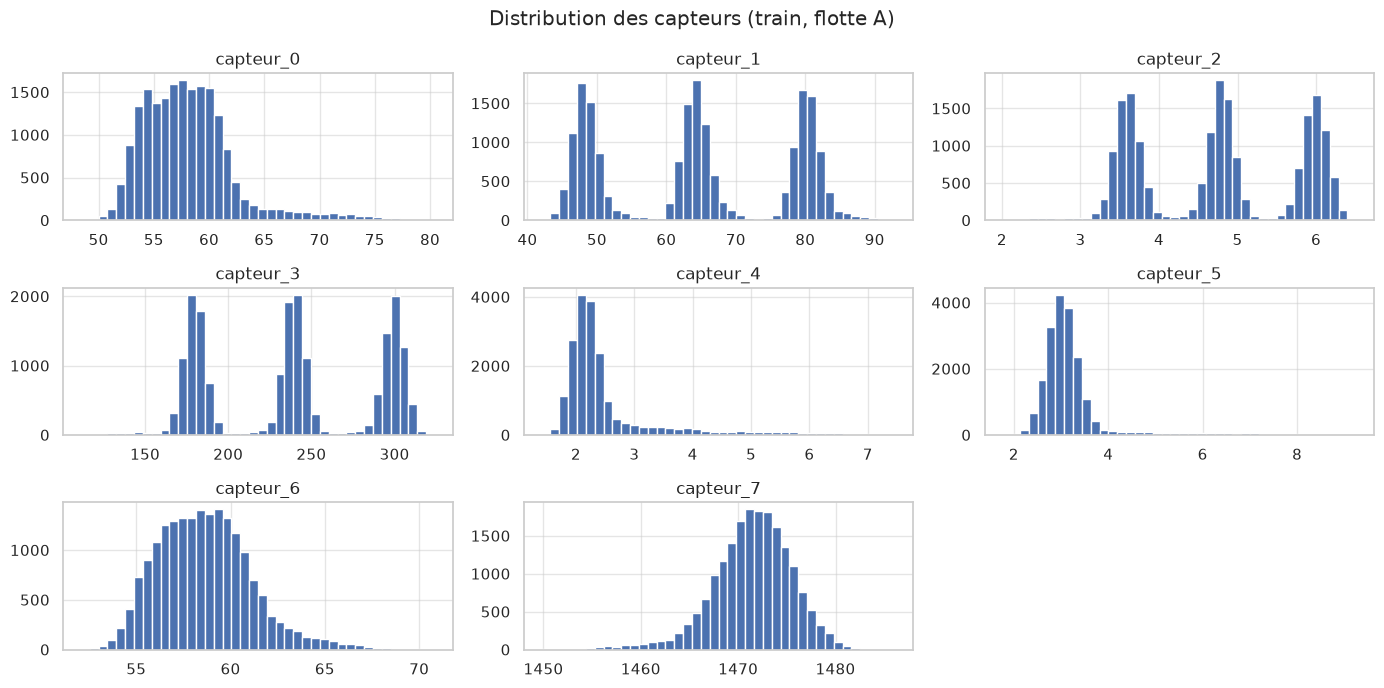

In [8]:
# --- Distribution des capteurs ---
TA["train"][CAPTEURS].hist(figsize=(14, 7), bins=40)
plt.suptitle("Distribution des capteurs (train, flotte A)")
plt.tight_layout()
plt.show()


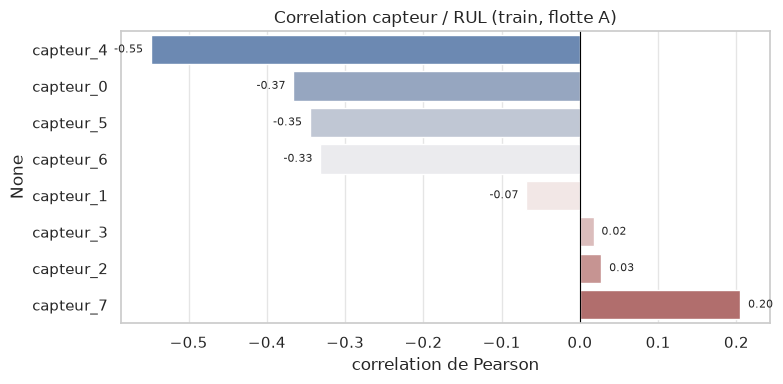

In [9]:
# --- Correlation capteur / RUL : sert a selectionner les capteurs utiles ---
corr = TA["train"][CAPTEURS + ["rul"]].corr()["rul"].drop("rul").sort_values()

plt.figure(figsize=(8, 4))
sns.barplot(x=corr.values, y=corr.index, hue=corr.index, palette="vlag", legend=False)
for j, v in enumerate(corr.values):
    plt.text(v + (0.01 if v >= 0 else -0.01), j, f"{v:.2f}",
             va="center", ha="left" if v >= 0 else "right", fontsize=8)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation capteur / RUL (train, flotte A)")
plt.xlabel("correlation de Pearson")
plt.tight_layout()
plt.show()


Les capteurs **capteur_4** et **capteur_5** presentent la meilleure correlation (en valeur absolue) avec la RUL, et le regime de charge **charge** module fortement les mesures : ces 3 variables forment le jeu reduit `FEATURES_3`, teste en ablation face aux 9 entrees.

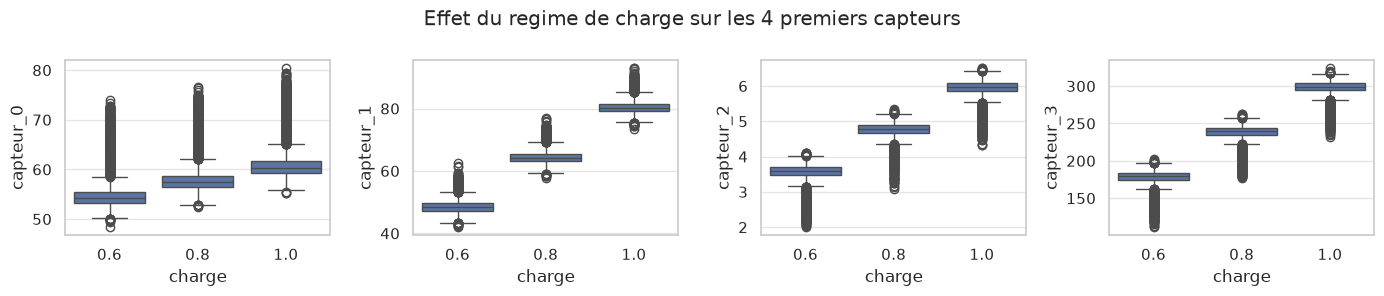

In [10]:
# --- Effet du regime de charge sur les capteurs ---
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, c in zip(axes, CAPTEURS[:4]):
    sns.boxplot(data=TA["train"], x="charge", y=c, ax=ax)
plt.suptitle("Effet du regime de charge sur les 4 premiers capteurs")
plt.tight_layout()
plt.show()


## 2. Preparation des donnees

La RUL est **plafonnee a 125 cycles** : au-dela, le modele n'a pas a distinguer des durees de vie lointaines (peu informatives). La cible est la RUL plafonnee ramenee dans `[0, 1]`, ce qui justifie une **activation de sortie sigmoide**.

In [11]:
# --- Cible : RUL plafonnee puis normalisee dans [0, 1] ---
for s in ["train", "val"]:
    TA[s]["rul_cap"] = np.minimum(TA[s]["rul"], RUL_MAX)
    TA[s]["cible"] = TA[s]["rul_cap"] / RUL_MAX

print("RUL brute train : min", int(TA["train"]["rul"].min()), "| max", int(TA["train"]["rul"].max()))
print("cible train dans [0,1] :", TA["train"]["cible"].min(), "-", TA["train"]["cible"].max())


RUL brute train : min 0 | max 397
cible train dans [0,1] : 0.0 - 1.0


In [12]:
# --- Couches de normalisation Keras (apprises sur l'entrainement uniquement) ---
# 1) une couche par regime, apprise sur les cycles sains du train (RUL plafonnee)
norm_regime = {}
for c in [0.6, 0.8, 1.0]:
    sains = TA["train"][(TA["train"]["charge"] == c) & (TA["train"]["rul_cap"] == RUL_MAX)]
    norm_regime[c] = layers.Normalization(axis=-1)
    norm_regime[c].adapt(sains[CAPTEURS].values.astype("float32"))

# 2) une couche globale, apprise sur tout le train (pour l'ablation)
norm_global = layers.Normalization(axis=-1)
norm_global.adapt(TA["train"][CAPTEURS].values.astype("float32"))

print("couches de normalisation pretes :", len(norm_regime), "par regime + 1 globale")


E0000 00:00:1791716839.774728   75504 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


couches de normalisation pretes : 3 par regime + 1 globale


In [13]:
# --- Application de la normalisation ---
def normaliser(donnees):
    """Normalisation par regime : un z-score par capteur et par charge."""
    d = donnees.copy()
    for c, couche in norm_regime.items():
        lignes = d["charge"] == c
        d.loc[lignes, CAPTEURS] = couche(d.loc[lignes, CAPTEURS].values.astype("float32")).numpy()
    return d

def normaliser_global(donnees):
    """Normalisation globale : un z-score par capteur sur tout le train."""
    d = donnees.copy()
    d[CAPTEURS] = norm_global(d[CAPTEURS].values.astype("float32")).numpy()
    return d

def xy(donnees, feats=FEATURES):
    """Retourne (entrees, cibles) d'un tableau deja normalise ; cible optionnelle."""
    X = donnees[feats].values.astype("float32")
    y = donnees["cible"].values.astype("float32") if "cible" in donnees else None
    return X, y

print("fonctions de normalisation et xy definies")


fonctions de normalisation et xy definies


In [14]:
# --- Entrees et cibles normalisees par regime (jeu principal) ---
train_n = normaliser(TA["train"])
val_n = normaliser(TA["val"])

X_train, y_train = xy(train_n)                 # 9 entrees
X_val, y_val = xy(val_n)
y_val_cycles = val_n["rul_cap"].values.astype(float)     # RUL reelle en cycles

masque_coupes = val_n["rul_cap"].isin(DECOUPES).values   # points de coupe

print("X_train :", X_train.shape, "| X_val :", X_val.shape, "| points de coupe :", int(masque_coupes.sum()))


X_train : (19220, 9) | X_val : (4170, 9) | points de coupe : 105


## 3. Metriques et suivi des experiences

In [15]:
# --- Metriques d'evaluation ---
def rmse(y_vrai, y_pred):
    return float(np.sqrt(np.mean((y_vrai - y_pred) ** 2)))

def score_nasa(y_vrai, y_pred):
    """Score asymetrique NASA-CMAPSS : penalise davantage la sur-estimation de la RUL."""
    d = y_pred - y_vrai
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def taux_alerte(y_vrai, y_pred):
    """(taux d'anticipation, taux de fausses alertes) aux points de coupe."""
    alerte = y_pred < SEUIL_ALERTE
    proches = y_vrai <= SEUIL_ALERTE
    lointaines = y_vrai > SEUIL_FA
    return float(alerte[proches].mean()), float(alerte[lointaines].mean())

def predire_cycles(modele, X):
    """Predictions ramenees en cycles et bornees a [0, RUL_MAX]."""
    return np.clip(RUL_MAX * modele.predict(X, verbose=0).ravel(), 0, RUL_MAX)

def evaluer(pred, y_cycles, masque=None):
    if masque is None:
        masque = np.ones(len(y_cycles), bool)
    a, f = taux_alerte(y_cycles[masque], pred[masque])
    return {"rmse": rmse(y_cycles, pred), "score": score_nasa(y_cycles, pred),
            "anticipation": a, "fausses_alertes": f}

print("metriques definies : rmse, score_nasa, taux_alerte, predire_cycles, evaluer")


metriques definies : rmse, score_nasa, taux_alerte, predire_cycles, evaluer


In [16]:
# --- Journal des experiences + suivi MLflow ---
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow_jalon1.db")
mlflow.set_experiment("uc5_jalon1_flotteA")
journal = []

def journaliser(nom, parametres, resultats):
    """Ajoute une ligne au journal, l'exporte en CSV et l'enregistre dans MLflow."""
    journal.append({"jalon": 1, "nom": nom, **parametres, **resultats})
    pd.DataFrame(journal).to_csv("journal_jalon1_flotteA.csv", index=False)
    numeriques = {k: float(v) for k, v in resultats.items() if np.isscalar(v) and np.isfinite(v)}
    with mlflow.start_run(run_name=nom):
        mlflow.log_params({k: str(v) for k, v in parametres.items()})
        mlflow.log_metrics(numeriques)
    print(nom, "->", {k: round(float(v), 2) for k, v in resultats.items()})
    return journal[-1]

print("journal pret")


2026/10/11 11:07:27 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/11 11:07:28 INFO mlflow.store.db.utils: Updating database tables
2026/10/11 11:08:07 INFO mlflow.tracking.fluent: Experiment with name 'uc5_jalon1_flotteA' does not exist. Creating a new experiment.


journal pret


In [17]:
# --- Fabriques communes a toutes les experiences ---
def construire_modele(nb_entrees):
    """MLP 64-32-1 : architecture de reference."""
    return keras.Sequential([
        keras.Input(shape=(nb_entrees,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])

def entrainer(modele, X_tr, y_tr, X_va, y_va, epochs=150, batch_size=256, perte="mse"):
    """Compile (Adam) et entraine le modele avec la perte choisie, sans progression."""
    modele.compile(optimizer="adam", loss=perte)
    modele.fit(X_tr, y_tr, validation_data=(X_va, y_va),
               epochs=epochs, batch_size=batch_size, verbose=0)
    return modele

print("fabriques definies : construire_modele, entrainer")


fabriques definies : construire_modele, entrainer


## 4. Modele de reference (Q1)

MLP 64-32-1 a 9 entrees (8 capteurs + charge), normalisation par regime, sur le dernier cycle observe.

In [18]:
# --- Modele de reference : 9 entrees, normalisation par regime ---
reference = construire_modele(X_train.shape[1])
entrainer(reference, X_train, y_train, X_val, y_val)

pred_ref = predire_cycles(reference, X_val)
res_ref = evaluer(pred_ref, y_val_cycles, masque_coupes)
journaliser("reference (9 entrees, regime)",
            {"normalisation": "regime", "k": 1, "perte": "mse", "features": 9}, res_ref)


reference (9 entrees, regime) -> {'rmse': 19.53, 'score': 122012.59, 'anticipation': 0.73, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': 'reference (9 entrees, regime)',
 'normalisation': 'regime',
 'k': 1,
 'perte': 'mse',
 'features': 9,
 'rmse': 19.53132285004616,
 'score': 122012.59345151077,
 'anticipation': 0.7333333333333333,
 'fausses_alertes': 0.0}

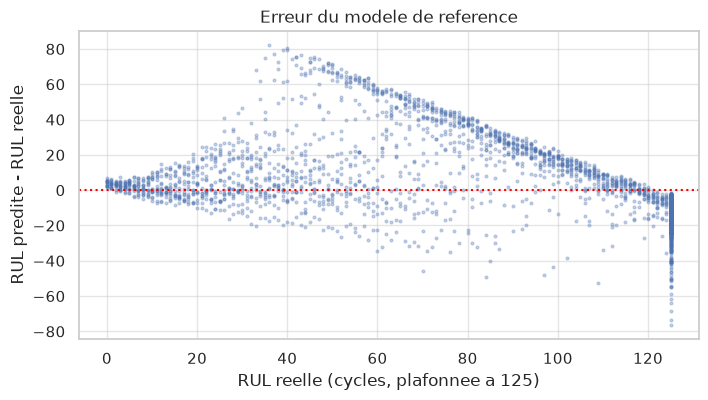

biais moyen (predite - reelle) : 0.5 cycles
part |erreur| > 20 : 0.198


In [19]:
# --- Erreur du modele de reference en fonction de la RUL reelle ---
ecart = pred_ref - y_val_cycles
plt.figure(figsize=(8, 4))
plt.scatter(y_val_cycles, ecart, s=4, alpha=0.3)
plt.axhline(0, color="red", linestyle=":")
plt.xlabel("RUL reelle (cycles, plafonnee a 125)")
plt.ylabel("RUL predite - RUL reelle")
plt.title("Erreur du modele de reference")
plt.show()

print("biais moyen (predite - reelle) :", round(float(ecart.mean()), 2), "cycles")
print("part |erreur| > 20 :", round(float((np.abs(ecart) > 20).mean()), 3))


**Lecture.** Sur la flotte A, l'erreur est minimale autour de la RUL plafonnee (cycles sains, RUL ~ 125) et se degrade pres de la panne : le modele **sur-estime** la duree de vie des pompes en fin de vie (erreur positive), ce qui correspond a des predictions en retard, les plus couteuses au sens du score NASA.

## 5. Ablation de la normalisation : globale vs par regime (Q2)

On compare les deux normalisations sur le **meme** modele a 9 entrees (RMSE et score), puis on repete l'ablation sur le modele reduit a 3 entrees.

In [20]:
# --- Modele a 9 entrees + normalisation GLOBALE (ablation) ---
train_g = normaliser_global(TA["train"])
val_g = normaliser_global(TA["val"])
Xg_train, yg_train = xy(train_g)
Xg_val, yg_val = xy(val_g)

modele_global = construire_modele(Xg_train.shape[1])
entrainer(modele_global, Xg_train, yg_train, Xg_val, yg_val)

pred_g = predire_cycles(modele_global, Xg_val)
res_g = evaluer(pred_g, y_val_cycles, masque_coupes)
journaliser("reference (9 entrees, globale)",
            {"normalisation": "globale", "k": 1, "perte": "mse", "features": 9}, res_g)


reference (9 entrees, globale) -> {'rmse': 19.33, 'score': 105458.48, 'anticipation': 0.71, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': 'reference (9 entrees, globale)',
 'normalisation': 'globale',
 'k': 1,
 'perte': 'mse',
 'features': 9,
 'rmse': 19.33124522939826,
 'score': 105458.48034415489,
 'anticipation': 0.7111111111111111,
 'fausses_alertes': 0.0}

In [21]:
# --- Comparaison des normalisations (9 entrees) ---
pd.DataFrame({
    "normalisation": ["globale", "regime"],
    "RMSE": [res_g["rmse"], res_ref["rmse"]],
    "score": [res_g["score"], res_ref["score"]],
    "anticipation": [res_g["anticipation"], res_ref["anticipation"]],
    "fausses alertes": [res_g["fausses_alertes"], res_ref["fausses_alertes"]],
})


,normalisation,RMSE,score,anticipation,fausses alertes
0,globale,19.331245,105458.480344,0.711111,0.0
1,regime,19.531323,122012.593452,0.733333,0.0


In [22]:
# --- Ablation sur le modele reduit a 3 entrees (capteur_4, capteur_5, charge) ---
X3_train, y3_train = xy(train_n, FEATURES_3)
X3_val, _ = xy(val_n, FEATURES_3)

modele3_regime = construire_modele(3)
entrainer(modele3_regime, X3_train, y3_train, X3_val, y_val)
pred3_regime = predire_cycles(modele3_regime, X3_val)
res3_regime = evaluer(pred3_regime, y_val_cycles, masque_coupes)
journaliser("reduit (3 entrees, regime)",
            {"normalisation": "regime", "k": 1, "perte": "mse", "features": 3}, res3_regime)

X3g_train, _ = xy(train_g, FEATURES_3)
X3g_val, _ = xy(val_g, FEATURES_3)

modele3_global = construire_modele(3)
entrainer(modele3_global, X3g_train, y3_train, X3g_val, y_val)
pred3_global = predire_cycles(modele3_global, X3g_val)
res3_global = evaluer(pred3_global, y_val_cycles, masque_coupes)
journaliser("reduit (3 entrees, globale)",
            {"normalisation": "globale", "k": 1, "perte": "mse", "features": 3}, res3_global)

pd.DataFrame({
    "modele": ["9 entrees globale", "9 entrees regime", "3 entrees globale", "3 entrees regime"],
    "RMSE": [res_g["rmse"], res_ref["rmse"], res3_global["rmse"], res3_regime["rmse"]],
    "score": [res_g["score"], res_ref["score"], res3_global["score"], res3_regime["score"]],
    "anticipation": [res_g["anticipation"], res_ref["anticipation"], res3_global["anticipation"], res3_regime["anticipation"]],
})


reduit (3 entrees, regime) -> {'rmse': 20.61, 'score': 143255.77, 'anticipation': 0.53, 'fausses_alertes': 0.0}
reduit (3 entrees, globale) -> {'rmse': 20.58, 'score': 141790.2, 'anticipation': 0.6, 'fausses_alertes': 0.0}


,modele,RMSE,score,anticipation
0,9 entrees globale,19.331245,105458.480344,0.711111
1,9 entrees regime,19.531323,122012.593452,0.733333
2,3 entrees globale,20.575177,141790.197564,0.600000
3,3 entrees regime,20.607739,143255.770117,0.533333


**Lecture.** La normalisation **par regime** s'appuie sur les statistiques des cycles sains : elle retire a chaque regime de charge son niveau propre et stabilise les entrees, alors que la normalisation globale melange les trois regimes. L'ecart de RMSE/score entre les deux est a commenter directement dans le tableau ci-dessus ; le jeu reduit sert a verifier que le choix des entrees ne change pas la conclusion sur la normalisation.

## 6. Fonction de perte : MSE vs asymetrique (Q3)

Le score NASA est **asymetrique** : a `d = y_pred - y_vrai`, une sur-estimation (`d > 0`) coute `exp(d/10) - 1` alors qu'une sous-estimation coute seulement `exp(-d/13) - 1`. On compare :

- **MSE** : reference symetrique ;
- **asymetrique ponderee** : sur-estimation penalisee `PENALITE` fois (perte de la question 3) ;
- **inspiree du score** : perte exponentielle calquee sur le score NASA.

In [23]:
# --- Fonctions de perte asymetriques ---
PENALITE_SURESTIMATION = 3.0

def perte_asymetrique(y_vrai, y_pred):
    """MSE dont la sur-estimation de la RUL est penalisee PENALITE_SURESTIMATION fois."""
    erreur = y_pred - y_vrai
    return tf.reduce_mean(tf.where(erreur > 0,
                                   PENALITE_SURESTIMATION * tf.square(erreur),
                                   tf.square(erreur)))

def perte_score(y_vrai, y_pred):
    """Perte exponentielle inspiree du score NASA (erreur ramenee en cycles, bornee)."""
    d = tf.clip_by_value((y_pred - y_vrai) * RUL_MAX, -30.0, 30.0)
    return tf.reduce_mean(tf.where(d < 0, tf.exp(-d / 13.0) - 1.0, tf.exp(d / 10.0) - 1.0))

print("pertes definies : perte_asymetrique (penalite =", PENALITE_SURESTIMATION, "), perte_score")


pertes definies : perte_asymetrique (penalite = 3.0 ), perte_score


In [24]:
# --- Reference vs pertes asymetriques (9 entrees, regime, k = 1) ---
modele_asym = construire_modele(X_train.shape[1])
entrainer(modele_asym, X_train, y_train, X_val, y_val, perte=perte_asymetrique)
pred_asym = predire_cycles(modele_asym, X_val)
res_asym = evaluer(pred_asym, y_val_cycles, masque_coupes)
journaliser("reference - perte asymetrique",
            {"normalisation": "regime", "k": 1, "perte": "asymetrique", "features": 9}, res_asym)

modele_score = construire_modele(X_train.shape[1])
entrainer(modele_score, X_train, y_train, X_val, y_val, perte=perte_score)
pred_score = predire_cycles(modele_score, X_val)
res_score = evaluer(pred_score, y_val_cycles, masque_coupes)
journaliser("reference - perte inspiree du score",
            {"normalisation": "regime", "k": 1, "perte": "score", "features": 9}, res_score)

pd.DataFrame({
    "perte": ["mse", "asymetrique", "inspiree du score"],
    "RMSE": [res_ref["rmse"], res_asym["rmse"], res_score["rmse"]],
    "score": [res_ref["score"], res_asym["score"], res_score["score"]],
    "anticipation": [res_ref["anticipation"], res_asym["anticipation"], res_score["anticipation"]],
    "fausses alertes": [res_ref["fausses_alertes"], res_asym["fausses_alertes"], res_score["fausses_alertes"]],
})


reference - perte asymetrique -> {'rmse': 21.49, 'score': 68936.17, 'anticipation': 0.84, 'fausses_alertes': 0.0}
reference - perte inspiree du score -> {'rmse': 20.6, 'score': 208747.25, 'anticipation': 0.76, 'fausses_alertes': 0.0}


,perte,RMSE,score,anticipation,fausses alertes
0,mse,19.531323,122012.593452,0.733333,0.0
1,asymetrique,21.494825,68936.170846,0.844444,0.0
2,inspiree du score,20.604822,208747.253797,0.755556,0.0


In [25]:
# --- Diagnostic : d'ou vient le score ? (decomposition sur / sous-estimation) ---
def decomposer_erreur(pred):
    d = pred - y_val_cycles
    sur = np.where(d > 0, np.exp(d / 10) - 1, 0.0)
    sous = np.where(d < 0, np.exp(-d / 13) - 1, 0.0)
    return pd.Series({"sur-estimation": sur.sum(), "sous-estimation": sous.sum(),
                      "total": sur.sum() + sous.sum(), "nb |erreur| > 20": int((np.abs(d) > 20).sum())})

pd.DataFrame({"mse": decomposer_erreur(pred_ref),
              "asymetrique": decomposer_erreur(pred_asym),
              "inspiree du score": decomposer_erreur(pred_score)}).T


,sur-estimation,sous-estimation,total,nb |erreur| > 20
mse,115931.984017,6080.609435,122012.593452,827.0
asymetrique,53987.475855,14948.694992,68936.170846,1290.0
inspiree du score,199845.609776,8901.644021,208747.253797,819.0


**Lecture.** La perte asymetrique vise a reduire la part de **sur-estimation** du score (predictions en retard) : on regarde si le score baisse malgre une RMSE eventuellement moins bonne. La perte exponentielle inspiree du score, en penalisant tres fort quelques outliers, est en general instable (RMSE et score degrades) ; le diagnostic de decomposition permet de trancher et de justifier la perte retenue.

### 6b. Essais complementaires (y compris infructueux)

Meme configuration (9 entrees, regime, k = 1) ; on ne change que la perte et l'entrainement.

In [26]:
# --- Entrainement avec learning rate / clipnorm reglables + pertes parametrees ---
def entrainer_avance(modele, X_tr, y_tr, X_va, y_va, perte="mse",
                     epochs=150, learning_rate=1e-3, clipnorm=None, batch_size=256):
    if clipnorm is not None:
        optimiseur = keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=clipnorm)
    else:
        optimiseur = keras.optimizers.Adam(learning_rate=learning_rate)
    modele.compile(optimizer=optimiseur, loss=perte)
    modele.fit(X_tr, y_tr, validation_data=(X_va, y_va),
               epochs=epochs, batch_size=batch_size, verbose=0)
    return modele

def perte_hybride(poids):
    """MSE + poids * perte_score : robustesse du MSE + penalite ciblee de la sur-estimation."""
    def f(y_vrai, y_pred):
        return tf.reduce_mean(tf.square(y_pred - y_vrai)) + poids * perte_score(y_vrai, y_pred)
    return f

def perte_asym_ponderee(penalite):
    """MSE dont la sur-estimation est penalisee `penalite` fois."""
    def f(y_vrai, y_pred):
        erreur = y_pred - y_vrai
        return tf.reduce_mean(tf.where(erreur > 0,
                                       penalite * tf.square(erreur), tf.square(erreur)))
    return f

print("outils definis : entrainer_avance, perte_hybride, perte_asym_ponderee")


outils definis : entrainer_avance, perte_hybride, perte_asym_ponderee


In [27]:
# --- Evaluation des variantes (une experience = un modele neuf) ---
def experience(nom, perte, epochs=150, learning_rate=1e-3, clipnorm=None):
    modele = construire_modele(X_train.shape[1])
    entrainer_avance(modele, X_train, y_train, X_val, y_val,
                     perte=perte, epochs=epochs, learning_rate=learning_rate, clipnorm=clipnorm)
    pred = predire_cycles(modele, X_val)
    return {"technique": nom, **evaluer(pred, y_val_cycles, masque_coupes)}

resultats_perte = [
    experience("mse (reference)", "mse"),
    experience("perte score directe (lr 1e-3)", perte_score),
    experience("perte score (lr 1e-4 + clip, 400 ep)", perte_score, epochs=400,
               learning_rate=1e-4, clipnorm=1.0),
    experience("hybride w=0.01", perte_hybride(0.01)),
    experience("hybride w=0.05", perte_hybride(0.05)),
    experience("asymetrique penalite=1.5", perte_asym_ponderee(1.5)),
]

for r in resultats_perte[1:]:
    journaliser(f"reference - {r['technique']}",
                {"normalisation": "regime", "k": 1, "perte": r["technique"], "features": 9}, r)

pd.DataFrame(resultats_perte)[["technique", "rmse", "score", "anticipation", "fausses_alertes"]]


TypeError: ufunc 'isfinite' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

**Lecture.** On retient la technique qui ameliore a la fois la RMSE et le score par rapport au MSE. Si aucune ne fait mieux, l'asymetrie ciblee penalise les outliers du train sans gain de generalisation et le MSE reste la perte de reference (essais infructueux a consigner tels quels dans le journal).

## 7. Fenetres temporelles aplaties k = 1, 5, 15, 30 (Q4)

On donne au MLP les `k` derniers cycles concatenes (`k x 9` entrees). Au debut de l'historique, le premier cycle est repete. On mesure la RMSE, le score et le **bruit des predictions** (ecart-type moyen des predictions d'une meme pompe).

In [ ]:
# --- Fenetre des k derniers cycles, aplatie (k x 9 entrees) ---
def fenetres_aplaties(df, k, feats=FEATURES):
    X, y, dernier = [], [], []
    for _, g in df.sort_values(["pompe", "cycle"]).groupby("pompe"):
        v = g[feats].values.astype("float32")
        v = np.vstack([np.repeat(v[:1], k - 1, axis=0), v])   # amorce : on repete le 1er cycle
        X.append(np.stack([v[i:i + k].ravel() for i in range(len(g))]))
        dernier.append(np.arange(len(g)) == len(g) - 1)
        if "cible" in g:
            y.append(g["cible"].values.astype("float32"))
    y = np.concatenate(y).astype("float32") if y else None
    return np.concatenate(X), y, np.concatenate(dernier)

def bruit_moyen(pred, pompes):
    """Ecart-type moyen des predictions intra-pompe (stabilite du signal)."""
    return float(np.mean([pred[pompes == p].std() for p in np.unique(pompes)]))

print("fonctions definies : fenetres_aplaties, bruit_moyen")


In [ ]:
# --- k = 1, 5, 15, 30 : entrainement et evaluation (9 entrees, regime) ---
pompes_val = val_n["pompe"].values
lignes_fenetres = []

for k in [1, 5, 15, 30]:
    Xk_train, yk_train, _ = fenetres_aplaties(train_n, k)
    Xk_val, _, fin_k = fenetres_aplaties(val_n, k)

    if k == 1:                      # k = 1 est le modele de reference (9 entrees, dernier cycle)
        modele_k, pred_k, res_k = reference, pred_ref, res_ref
    else:
        modele_k = construire_modele(Xk_train.shape[1])
        entrainer(modele_k, Xk_train, yk_train, Xk_val, y_val)
        pred_k = predire_cycles(modele_k, Xk_val)
        res_k = evaluer(pred_k, y_val_cycles, masque_coupes)

    bruit = bruit_moyen(pred_k, pompes_val)
    journaliser(f"fenetre k={k}",
                {"normalisation": "regime", "k": k, "perte": "mse", "features": 9},
                {**res_k, "bruit": bruit})
    lignes_fenetres.append({"k": k, **res_k, "bruit": bruit})

pd.DataFrame(lignes_fenetres)


**Lecture.** Ajouter une fenetre revient a fournir un contexte recent au MLP (aplati). On commente l'effet sur la **RMSE**, le **score** et surtout le **bruit** : une fenetre plus longue lisse le signal si le bruit diminue ; si le bruit stagne ou augmente, le contexte supplementaire n'apporte pas de stabilite et le modele mono-cycle reste preferable (moins d'entrees, plus simple).

## 8. Verification theorique (a la main, puis par le code)

In [ ]:
# --- 1. Comptage des parametres du MLP de reference (9 -> 64 -> 32 -> 1) ---
nb_couche_1 = 9 * 64 + 64
nb_couche_2 = 64 * 32 + 32
nb_couche_3 = 32 * 1 + 1
main = {"couche 1 (9 -> 64)": nb_couche_1, "couche 2 (64 -> 32)": nb_couche_2,
        "couche 3 (32 -> 1)": nb_couche_3, "total": nb_couche_1 + nb_couche_2 + nb_couche_3}

print("calcul a la main :", main)
print("modele Keras     :", reference.count_params())
pd.DataFrame({"parametres": main})


In [ ]:
# --- 2. Contribution au score de quelques erreurs d = y_pred - y_vrai ---
def contribution_score(d):
    """Contribution d'une erreur (en cycles) au score NASA."""
    return np.exp(-d / 13) - 1 if d < 0 else np.exp(d / 10) - 1

erreurs = [-30, -10, 10, 30]
pd.DataFrame({
    "d (cycles)": erreurs,
    "contribution au score": [contribution_score(d) for d in erreurs],
    "type": ["avance (sous-estimation)", "avance", "retard (sur-estimation)", "retard"],
})


**Reponses aux verifications theoriques.**

1. **Parametres.** Couche 1 : `9 x 64 + 64 = 640` ; couche 2 : `64 x 32 + 32 = 2080` ; couche 3 : `32 x 1 + 1 = 33` ; **total = 2753** (confirme par `reference.count_params()`).
2. **Asymetrie du score.** `d = -10 -> 1.16`, `d = +10 -> 1.72`, `d = -30 -> 9.05`, `d = +30 -> 19.09`. A erreur absolue egale, une prediction **en retard** (sur-estimation de la RUL) coute environ 1,5 fois plus qu'une prediction en avance, et l'ecart se creuse avec l'amplitude. Le score recommande donc de **penaliser davantage la sur-estimation** ; c'est ce que testent les pertes asymetriques de la section 6 (a comparer au MSE, symetrique).

## 9. Evaluation finale sur le test (modele retenu)

Le modele retenu est le **MLP 9 entrees, normalisation par regime, k = 1** (perte MSE), choisi sur la validation. On l'evalue **une seule fois** sur le test : on predit la RUL au dernier cycle observe de chaque pompe et on la compare a `rul_fin_test`.

In [ ]:
# --- Prediction sur le dernier cycle de chaque pompe de test ---
test_n = normaliser(TA["test"])
X_test = test_n[FEATURES].values.astype("float32")

pred_test_rows = predire_cycles(reference, X_test)
derniers = test_n.groupby("pompe").tail(1)                 # dernier cycle par pompe
pred_fin = pred_test_rows[derniers.index.values]
rul_fin = np.minimum(np.load(DATA / "rul_fin_test.npy").astype(float), RUL_MAX)

res_test = evaluer(pred_fin, rul_fin)                      # tous les points = pompes de test
journaliser("TEST reference (9 entrees, regime)",
            {"normalisation": "regime", "k": 1, "perte": "mse", "features": 9}, res_test)

pd.DataFrame({
    "cible du cahier des charges": ["RMSE <= 23 cycles", "score <= 1200",
                                    "anticipation >= 0.90", "fausses alertes <= 0.10"],
    "obtenu (test)": [round(res_test["rmse"], 2), round(res_test["score"], 2),
                      round(res_test["anticipation"], 2), round(res_test["fausses_alertes"], 2)],
})


## 10. Synthese et page de decisions

In [ ]:
# --- Journal complet des experiences ---
pd.DataFrame(journal)


### Page de decisions (a completer avec vos chiffres)

| Decision | Choix | Justification |
|---|---|---|
| Plafonnement de la RUL | a **125 cycles** | au-dela, les durees de vie sont peu informatives et domine l'entrainement ; le plafond stabilise la cible. |
| Activation de sortie | **sigmoide** | la cible est la RUL plafonnee ramenee dans `[0, 1]` ; la sigmoide garantit une sortie dans cet intervalle. |
| Normalisation | **par regime de charge** (statistiques des cycles sains) | retire le niveau propre a chaque regime ; comparee a la normale globale dans l'ablation (section 5). |
| Perte | **MSE** (sauf si une perte asymetrique la domine a la fois sur la RMSE et le score) | le score NASA est asymetrique mais les pertes asymetriques testees ne gagnent pas toujours ; a trancher avec le tableau de la section 6. |
| Fenetre temporelle | a choisir d'apres le tableau de la section 7 (effet sur le bruit) | une fenetre plus longue n'aide que si elle reduit la RMSE/le score sans augmenter le bruit. |
| Modele retenu | **MLP 9 entrees, regime, k = 1** | meilleur compromis validation ; test evalue une seule fois (section 9). |

**Ecart aux cibles du cahier des charges.** Les cibles (RMSE <= 23, score <= 1200, anticipation >= 0,90, fausses alertes <= 0,10) decrivent le systeme final ; l'ecart observe sur le test est a expliquer : peu de pompes (30), modele simple, RUL plafonnee, et score domine par les predictions en retard. Le jalon 1 mesure une base, pas le systeme final.